<a href="https://colab.research.google.com/github/VladyslavBiblyi/CSC-349-OL1/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#1.
####First, I download the Pima Indians Diabetes dataset from Kaggle using kagglehub(I wasn't able to get it from UCI so had to do it that way). Then I load it into a Pandas DataFrame called pima and assign column names to make the data easier to work with.

In [14]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (VotingClassifier, BaggingClassifier,
    RandomForestClassifier, AdaBoostClassifier)

from sklearn.metrics import accuracy_score, classification_report

path = kagglehub.dataset_download("mragpavank/diabetes")

pima = pd.read_csv(os.path.join(path, "diabetes.csv"))

pima.columns = ["pregnancies", "glucose", "blood_pressure", "skin_thickness",
                "insulin", "bmi", "diabetes_pedigree", "age", "outcome"]

Using Colab cache for faster access to the 'diabetes' dataset.


#2.
####Here I use head(), info(), and describe() to check what the dataset looks like, what types of values it contains, and the basic statistics for each column. I also count the zeros in some medical measurements because those might actually be missing values.

In [15]:
display(pima.head())

pima.info()

display(pima.describe())

missing_columns = ["glucose", "blood_pressure", "skin_thickness","insulin", "bmi"]

print((pima[missing_columns] == 0).sum())

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pregnancies        768 non-null    int64  
 1   glucose            768 non-null    int64  
 2   blood_pressure     768 non-null    int64  
 3   skin_thickness     768 non-null    int64  
 4   insulin            768 non-null    int64  
 5   bmi                768 non-null    float64
 6   diabetes_pedigree  768 non-null    float64
 7   age                768 non-null    int64  
 8   outcome            768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
dtype: int64


#3.
####Some medical measurements have zeros that don't make sense as actual values. I replace these zeros with NaN and check how many missing values there are. Then I split the dataset into training and testing sets and use SimpleImputer to replace the missing values with the median of each column.

In [16]:
pima[missing_columns] = pima[missing_columns].replace(0, np.nan)

print("Missing Values:")
print(pima.isnull().sum())

X = pima.drop("outcome", axis=1)
y = pima["outcome"]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns)

X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns)

Missing Values:
pregnancies            0
glucose                5
blood_pressure        35
skin_thickness       227
insulin              374
bmi                   11
diabetes_pedigree      0
age                    0
outcome                0
dtype: int64


#4.
####I created a ColumnTransformer and a Pipeline to scale the numerical features using StandardScaler. This put the features on a similar scale. I fit the pipeline on the training data and use it to transform the test data.

In [17]:
preprocessor = ColumnTransformer([("num", StandardScaler(), X.columns)])

pipeline = Pipeline([("preprocessor", preprocessor)])

X_train_scaled = pipeline.fit_transform(X_train)
X_test_scaled = pipeline.transform(X_test)

#5.
####I used Logistic Regression, SVM, and Decision Tree models to create two Voting Classifiers. Hard voting chooses the prediction made by most models, while soft voting averages their predicted probabilities. I trained both classifiers, compared their test accuracy, printed classification reports, and created a bar chart to show the results.

Hard Voting Accuracy: 0.7344
              precision    recall  f1-score   support

           0       0.79      0.80      0.79       123
           1       0.63      0.62      0.63        69

    accuracy                           0.73       192
   macro avg       0.71      0.71      0.71       192
weighted avg       0.73      0.73      0.73       192

Soft Voting Accuracy: 0.7240
              precision    recall  f1-score   support

           0       0.81      0.74      0.77       123
           1       0.60      0.70      0.64        69

    accuracy                           0.72       192
   macro avg       0.71      0.72      0.71       192
weighted avg       0.74      0.72      0.73       192



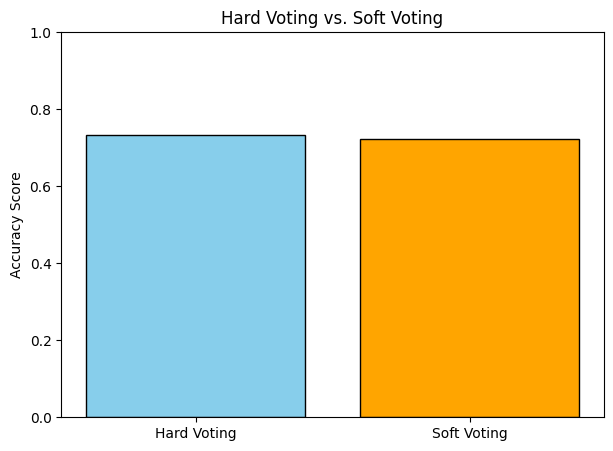

In [18]:
log_clf = LogisticRegression(random_state=42, max_iter=5000)
svm_clf = SVC(gamma="scale", probability=True, random_state=42)
tree_clf = DecisionTreeClassifier(random_state=42)

voting_clf_hard = VotingClassifier(estimators=[("lr", log_clf),("svc", svm_clf),
        ("tree", tree_clf)], voting="hard")

voting_clf_soft = VotingClassifier(estimators=[("lr", log_clf),("svc", svm_clf),
        ("tree", tree_clf)],voting="soft")

models = {"Hard Voting": voting_clf_hard, "Soft Voting": voting_clf_soft}

names = []
accuracies = []

for name, clf in models.items():
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)

    names.append(name)
    accuracies.append(acc)

    print(f"{name} Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred))

plt.figure(figsize=(7, 5))
plt.bar(
    names,
    accuracies,
    color=["skyblue", "orange"],
    edgecolor="black"
)

plt.ylabel("Accuracy Score")
plt.title("Hard Voting vs. Soft Voting")
plt.ylim(0, 1)
plt.show()

#6.
####Here I trained a Bagging Classifier using 500 Decision Trees and bootstrap sampling. I enabled out-of-bag evaluation, which tests the model using training samples that weren't included in each tree's bootstrap sample. Then I compared the OOB accuracy with the test accuracy and ploted both results.

OOB Accuracy: 0.7587
Test Accuracy: 0.7500


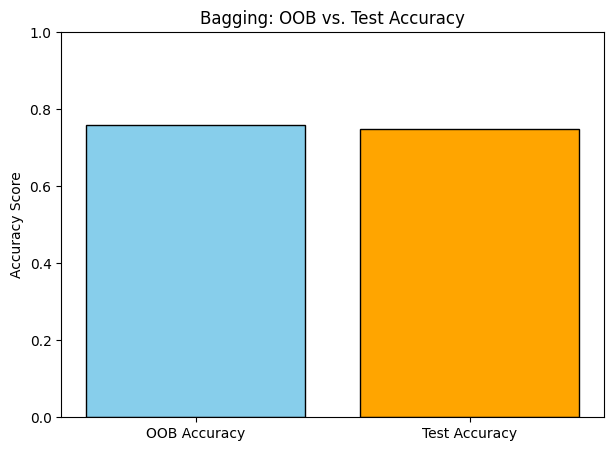

In [19]:
bag_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=500,
    bootstrap=True,
    oob_score=True,
    n_jobs=-1,
    random_state=42
)

bag_clf.fit(X_train_scaled, y_train)

oob_accuracy = bag_clf.oob_score_

y_pred = bag_clf.predict(X_test_scaled)
bag_test_accuracy = accuracy_score(y_test, y_pred)

print(f"OOB Accuracy: {oob_accuracy:.4f}")
print(f"Test Accuracy: {bag_test_accuracy:.4f}")

plt.figure(figsize=(7, 5))
plt.bar(
    ["OOB Accuracy", "Test Accuracy"],
    [oob_accuracy, bag_test_accuracy],
    color=["skyblue", "orange"],
    edgecolor="black"
)

plt.ylabel("Accuracy Score")
plt.title("Bagging: OOB vs. Test Accuracy")
plt.ylim(0, 1)
plt.show()

#7.
####I trained a RF Classifier using 500 Decision Trees with random feature selection. After training, I calculated its test accuracy and used a horizontal bar chart to show which medical features were the most important for the model's predictions.

Random Forest Accuracy: 0.75


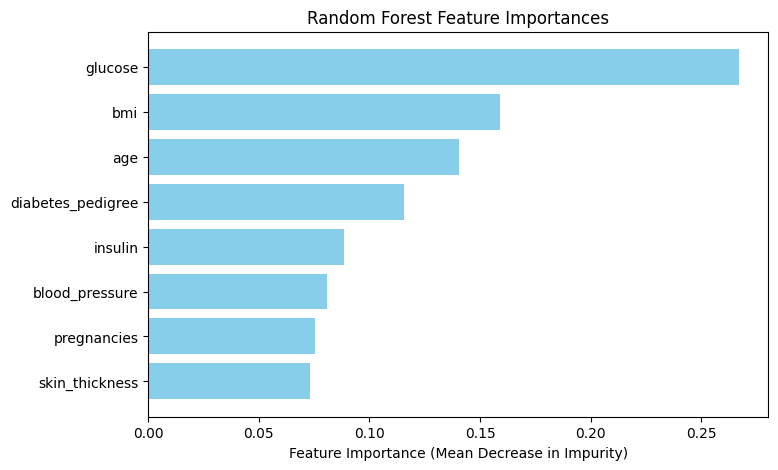

In [20]:
rnd_clf = RandomForestClassifier(
    n_estimators=500,
    max_features="sqrt",
    n_jobs=-1,
    random_state=42
)

rnd_clf.fit(X_train_scaled, y_train)

y_pred = rnd_clf.predict(X_test_scaled)

print("Random Forest Accuracy:", accuracy_score(y_test, y_pred))

importances = pd.Series(rnd_clf.feature_importances_,index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(importances.index, importances.values, color="skyblue")

plt.xlabel("Feature Importance (Mean Decrease in Impurity)")
plt.title("Random Forest Feature Importances")
plt.show()

#8.
####Finally, I trained an AdaBoost Classifier using decision stumps, which are Decision Trees with a maximum depth of one. AdaBoost trains the trees one after another and gives more attention to samples that previous trees predicted incorrectly. I compared training and test accuracy to check how well the model performs on new data and whether it might be overfitting.

Training Accuracy: 0.7882
Test Accuracy: 0.7604


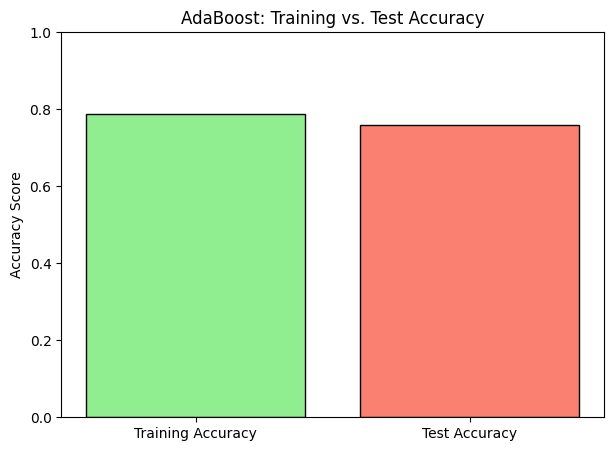

In [21]:
ada_clf = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=30,
    learning_rate=0.5,
    random_state=42
)

ada_clf.fit(X_train_scaled, y_train)

train_accuracy = ada_clf.score(X_train_scaled, y_train)
test_accuracy = ada_clf.score(X_test_scaled, y_test)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

plt.figure(figsize=(7, 5))
plt.bar(
    ["Training Accuracy", "Test Accuracy"],
    [train_accuracy, test_accuracy],
    color=["lightgreen", "salmon"],
    edgecolor="black"
)

plt.ylabel("Accuracy Score")
plt.title("AdaBoost: Training vs. Test Accuracy")
plt.ylim(0, 1)
plt.show()